Population Growth Analysis of Washington State Using Logistic Growth Model (1910-2020)

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

Input populasi data

In [43]:
data = pd.DataFrame({
    "Name": ['Washington']*12,
    "Type": ['State']*12,
    "Year": [1910, 1920, 1930, 1940, 1950, 1960, 1970, 1980, 1990,2000, 2010, 2020],
    "Pop": [1141990, 1356621, 1563396, 1736191, 2378963, 2853214, 3409169, 4132156, 4866692, 5894121, 6724540, 7705281]
})

data

,Name,Type,Year,Pop
0,Washington,State,1910,1141990
1,Washington,State,1920,1356621
2,Washington,State,1930,1563396
3,Washington,State,1940,1736191
4,Washington,State,1950,2378963
5,Washington,State,1960,2853214
6,Washington,State,1970,3409169
7,Washington,State,1980,4132156
8,Washington,State,1990,4866692
9,Washington,State,2000,5894121


Waktu dan populasi data

In [44]:
t_data = data["Year"].to_numpy()
t_data = t_data - t_data[0]

y_data = data["Pop"].to_numpy()

print("t_data =", t_data)
print("y_data =", y_data)

t_data = [  0  10  20  30  40  50  60  70  80  90 100 110]
y_data = [1141990 1356621 1563396 1736191 2378963 2853214 3409169 4132156 4866692
 5894121 6724540 7705281]


Model logistik

In [45]:
def f_logistic(t, a, b, N0):
    return (a / b) / (1.0 + ((a - b * N0) / (b * N0)) * np.exp(-a * t))

In [46]:
def obj_residual_squared(theta):
    a = np.exp(theta[0])
    b = np.exp(theta[1])
    N0 = np.exp(theta[2])
    y_pred = f_logistic(t_data, a, b, N0)
    resid = y_data - y_pred
    return np.sum(resid**2)

Perkiraan awal untum optimasi

In [47]:
K0 = max(np.max(y_data), 1e-3)
a0 = 0.1
b0 = a0 / (K0 + 1e-6)
N00 = max(y_data[0], 1e-3)
theta0 = np.log([a0, b0, N00])

print("Initial guess:")
print("a0  =", a0)
print("b0  =", b0)
print("N00 =", N00)

Initial guess:
a0  = 0.1
b0  = 1.2978112024725254e-08
N00 = 1141990


Optimasi

In [48]:
result = minimize(
    obj_residual_squared,
    theta0,
    method='BFGS',
    options={'maxiter': 10000, 'gtol': 1e-8, 'disp': True}
)

         Current function value: 74103839736.144455
         Iterations: 46
         Function evaluations: 385
         Gradient evaluations: 94


/usr/local/lib/python3.13/dist-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


In [49]:
theta_hat = result.x
a_hat = np.exp(theta_hat[0])
b_hat = np.exp(theta_hat[1])
N0_hat = np.exp(theta_hat[2])
K_hat = a_hat / b_hat
rss = result.fun

print("Estimated parameters:")
print(f"a  = {a_hat:.6f}")
print(f"b  = {b_hat:.8e}")
print(f"N0 = {N0_hat:.6f}")
print(f"Carrying capacity = {K_hat:.6f}")
print(f"Residual sum of squares = {rss:.4f}")

Estimated parameters:
a  = 0.022440
b  = 1.15144167e-09
N0 = 1031249.066323
Carrying capacity = 19488558.881327
Residual sum of squares = 74103839736.1445


Menghitung model populasi

In [50]:
y_pred = f_logistic(t_data, a_hat, b_hat, N0_hat)
hasil = pd.DataFrame({
    "Year": data["Year"],
    "Pop Aktual": y_data,
    "Pop Model": y_pred
})

hasil

,Year,Pop Aktual,Pop Model
0,1910,1141990,1.031249e+06
1,1920,1356621,1.273725e+06
2,1930,1563396,1.568370e+06
3,1940,1736191,1.923974e+06
4,1950,2378963,2.349635e+06
5,1960,2853214,2.854166e+06
6,1970,3409169,3.445256e+06
7,1980,4132156,4.128378e+06
8,1990,4866692,4.905532e+06
9,2000,5894121,5.773990e+06


Menghitung MAPE

In [51]:
y_true = y_data
y_pred = f_logistic(t_data, a_hat, b_hat, N0_hat)

MAPE = np.mean(
    np.abs((y_true - y_pred)
    / y_true)) * 100
print(f"MAPE = {MAPE:.2f}%")

MAPE = 2.73%


Plot data aktual and model logistik

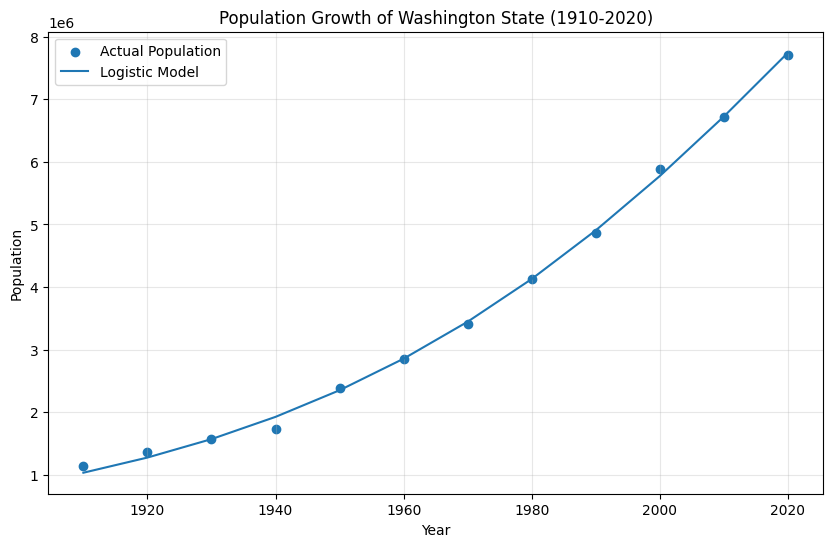

In [52]:
plt.figure(figsize=(10, 6))
plt.scatter(data["Year"], y_data, label="Actual Population")
plt.plot(data["Year"], y_pred, label="Logistic Model")
plt.xlabel("Year")
plt.ylabel("Population")
plt.title("Population Growth of Washington State (1910-2020)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Membagi data training dan testing

In [58]:
train_mask = data["Year"] <= 1980
test_mask = data["Year"] > 1980

t_train = t_data[train_mask]
y_train = y_data[train_mask]

t_test = t_data[test_mask]
y_test = y_data[test_mask]

print("Data Training:", len(y_train))
print("Data Testing:", len(y_test))

Data Training: 8
Data Testing: 4


In [54]:
def obj_residual_squared(theta):
    a = np.exp(theta[0])
    b = np.exp(theta[1])
    N0 = np.exp(theta[2])

    y_pred = f_logistic(t_train, a, b, N0)
    resid = y_train - y_pred

    return np.sum(resid**2)

In [55]:
result = minimize(
    obj_residual_squared,
    theta0,
    method='BFGS',
    options={'maxiter': 10000, 'gtol': 1e-8, 'disp': True}
)

theta_hat = result.x

a_hat = np.exp(theta_hat[0])
b_hat = np.exp(theta_hat[1])
N0_hat = np.exp(theta_hat[2])

K_hat = a_hat / b_hat

         Current function value: 44428649095.745438
         Iterations: 76
         Function evaluations: 448
         Gradient evaluations: 112


/usr/local/lib/python3.13/dist-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


In [56]:
# Prediksi data testing
y_pred_test = f_logistic(
    t_test, a_hat, b_hat, N0_hat
)

# Menghitung MAPE testing
MAPE_test = np.mean(
    np.abs((y_test - y_pred_test) / y_test)
) * 100

print("MAPE Testing =", round(MAPE_test, 2), "%")

MAPE Testing = 7.77 %


In [59]:
hasil_testing = pd.DataFrame({
    "Year": data.loc[test_mask, "Year"].values,
    "Populasi Aktual": y_test,
    "Populasi Prediksi": y_pred_test
})

hasil_testing

,Year,Populasi Aktual,Populasi Prediksi
0,1990,4866692,5.009256e+06
1,2000,5894121,6.070882e+06
2,2010,6724540,7.357501e+06
3,2020,7705281,8.916797e+06


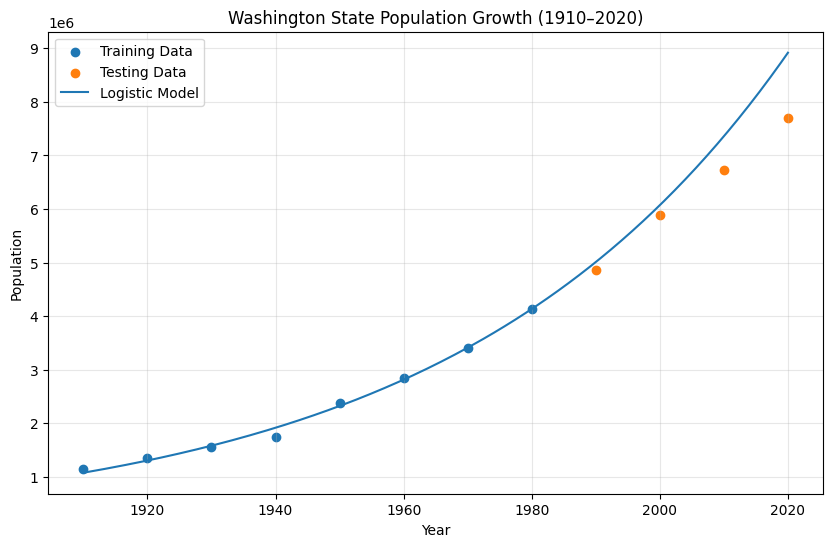

In [60]:
import matplotlib.pyplot as plt

# Membuat rentang waktu untuk kurva model
t_plot = np.linspace(min(t_data), max(t_data), 200)

# Menghitung prediksi model
y_plot = f_logistic(t_plot, a_hat, b_hat, N0_hat)

plt.figure(figsize=(10, 6))

# Data training
plt.scatter(
    data.loc[train_mask, "Year"],
    y_train,
    label="Training Data"
)

# Data testing
plt.scatter(
    data.loc[test_mask, "Year"],
    y_test,
    label="Testing Data"
)

# Kurva model logistik
plt.plot(
    data["Year"].min() + t_plot,
    y_plot,
    label="Logistic Model"
)

plt.xlabel("Year")
plt.ylabel("Population")
plt.title("Washington State Population Growth (1910–2020)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#Conclusion

This project analyzes the population growth of Washington State from 1910 to 2020 using the logistic growth model. The model was developed using training data from 1910 to 1980 and evaluated using testing data from 1990 to 2020. The model achieved a testing MAPE of 7.77%, indicating an average absolute percentage prediction error of 7.77% on the testing observations. These results show that the logistic growth model can represent the historical population growth pattern, although further evaluation is needed to assess its reliability for future predictions.